# 🌤️ Weather Forecasting — Foundation Pipeline

## End-to-End Data Acquisition, Time-Series Structuring & Deep EDA

**Location:** Cairo, Egypt (30.0444°N, 31.2357°E)  
**Period:** January 1, 2023 – December 31, 2025 (3 years, 1,096 daily records)  
**Splits:** Train = 731 rows (2023–2024, leap year), Test = 365 rows (2025)  
**API:** Open-Meteo Historical Weather Archive (free, keyless, ERA5 reanalysis)  
**Variables:** 7 daily features (cleaned, unscaled variables in physical units) — temperature (min/max/mean), precipitation, humidity, wind speed, cloud cover

---

This notebook walks through the three foundational pillars of the project:

| Part | Topic | Goal |
|------|-------|------|
| **1** | Data Acquisition | Fetch historical weather data from the Open-Meteo API |
| **2** | Dataset Preparation | Parse, validate, clean, and export the time-series |
| **3** | Deep Time-Series EDA | Uncover patterns, seasonality, stationarity, and anomalies |


## Setup & Imports

In [1]:
import sys
import os
import json
import logging

# Ensure the project root is on the Python path
PROJECT_ROOT = os.path.dirname(os.path.abspath('.'))
if os.path.basename(os.getcwd()) == 'notebooks':
    PROJECT_ROOT = os.path.dirname(os.getcwd())
else:
    PROJECT_ROOT = os.getcwd()
sys.path.insert(0, PROJECT_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Project modules
import config
from src import data_acquisition, data_preparation, eda

# Plotting setup
%matplotlib inline
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 150, 'figure.figsize': (14, 5)})

# Logging
logging.basicConfig(level=logging.INFO, format='%(levelname)-7s | %(name)s | %(message)s')

print(f'Project root: {PROJECT_ROOT}')
print(f'Location: {config.LOCATION_NAME}')
print(f'Period: {config.START_DATE} → {config.END_DATE}')

/home/mahmoud/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-28my4cod because there was an issue with the default path (/home/mahmoud/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Project root: /home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting
Location: Cairo, Egypt
Period: 2023-01-01 → 2025-12-31


---

# Part 1: Weather API Integration & Data Acquisition

We use the **Open-Meteo Historical Weather API** to fetch 3 years of daily weather records for Cairo.

### Why Open-Meteo?
| Criteria | Open-Meteo | OpenWeatherMap | NASA POWER |
|----------|-----------|----------------|------------|
| **Auth** | No API key | API key required | No key |
| **Cost** | Free (non-commercial) | Limited free tier | Free |
| **Historical depth** | Back to 1940 (ERA5) | 5 years max (free) | Back to 1981 |
| **Rate limit** | 10,000/day | 60/min (free) | 100/day |
| **Speed** | Fast (single call) | Paginated | Bulk download |

In [2]:
# Fetch weather data from the API
raw_data = data_acquisition.run()

INFO    | src.data_acquisition | =================================================================


INFO    | src.data_acquisition | PART 1 — DATA ACQUISITION


INFO    | src.data_acquisition | =================================================================


INFO    | src.data_acquisition | Request parameters built:


INFO    | src.data_acquisition |   Location  : Cairo, Egypt (30.0444, 31.2357)


...

INFO    | src.data_acquisition |   Variables : temperature_2m_max, temperature_2m_min, temperature_2m_mean, precipitation_sum, relative_humidity_2m_mean, wind_speed_10m_max, cloud_cover_mean


INFO    | src.data_acquisition |   Timezone  : Africa/Cairo


INFO    | src.data_acquisition | Raw JSON already exists at /home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting/data/raw/open_meteo_response.json. Loading existing immutable dataset.


INFO    | src.data_acquisition | Raw JSON already exists at /home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting/data/raw/open_meteo_response.json (106.0 KB) — preserving immutable artifact.


INFO    | src.data_acquisition | Part 1 complete.



In [3]:
# Inspect the raw response structure
print('Top-level keys:', list(raw_data.keys()))
print(f'\nLocation metadata:')
for key in ['latitude', 'longitude', 'timezone', 'elevation', 'generationtime_ms']:
    if key in raw_data:
        print(f'  {key}: {raw_data[key]}')

print(f'\nDaily variables: {list(raw_data["daily"].keys())}')
print(f'Number of records: {len(raw_data["daily"]["time"])}')
print(f'Date range: {raw_data["daily"]["time"][0]} → {raw_data["daily"]["time"][-1]}')

Top-level keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']

Location metadata:
  latitude: 30.052723
  longitude: 31.190199
  timezone: Africa/Cairo
  elevation: 22.0
  generationtime_ms: 547.147274017334

Daily variables: ['time', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'precipitation_sum', 'relative_humidity_2m_mean', 'wind_speed_10m_max', 'cloud_cover_mean']
Number of records: 1096
Date range: 2023-01-01 → 2025-12-31


In [4]:
# Preview raw data (first 5 days)
preview = {k: v[:5] for k, v in raw_data['daily'].items()}
pd.DataFrame(preview)

,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_max,cloud_cover_mean
0,2023-01-01,22.4,9.5,15.7,0.0,67,14.3,55
1,2023-01-02,22.3,9.1,15.1,0.0,74,11.1,3
2,2023-01-03,21.1,9.0,14.8,0.3,78,13.7,29
3,2023-01-04,20.6,10.6,15.4,0.5,75,13.5,37
4,2023-01-05,20.2,8.1,14.5,0.0,69,12.0,20


The raw JSON has been saved to `data/raw/open_meteo_response.json` for full reproducibility.

**API documentation:**
- **Endpoint:** `https://archive-api.open-meteo.com/v1/archive`
- **Parameters:** latitude, longitude, start_date, end_date, daily variables, timezone
- **Coordinates:** 30.0444°N, 31.2357°E (Cairo, Egypt)
- **Rate limit:** 10,000 requests/day — we used 1 request
- **Data source:** ECMWF ERA5 reanalysis

---

# Part 2: Time-Series Dataset Preparation

We now parse the raw JSON into a clean pandas DataFrame with:
1. Proper datetime indexing with explicit `freq='D'`
2. Continuity validation (no duplicates, no gaps)
3. Domain-appropriate missing value handling
4. Unit verification and physical bounds checking

In [5]:
# Run the full data preparation pipeline
df = data_preparation.run(raw_data)

INFO    | src.data_preparation | =================================================================


INFO    | src.data_preparation | PART 2 — DATA PREPARATION


INFO    | src.data_preparation | =================================================================


INFO    | src.data_preparation | DataFrame shape: (1096, 7)


INFO    | src.data_preparation | Date range: 2023-01-01 00:00:00 → 2025-12-31 00:00:00


...

INFO    | src.data_preparation |   ✓ humidity_pct: range [13.00, 78.00] % — within bounds [0, 100]


INFO    | src.data_preparation |   ✓ wind_speed_max_kmh: range [4.30, 36.20] km/h — within bounds [0, 200]


INFO    | src.data_preparation |   ✓ cloud_cover_pct: range [0.00, 100.00] % — within bounds [0, 100]


INFO    | src.data_preparation | Clean dataset already exists at /home/mahmoud/MY_SDD/cellula ML intern/weather-forecasting/data/processed/cairo_weather_clean.csv (48.6 KB, 1096 rows) — preserving existing verified dataset.


INFO    | src.data_preparation | Part 2 complete.



In [6]:
# Inspect the cleaned DataFrame
print(f'Shape: {df.shape}')
print(f'Index type: {type(df.index).__name__}')
print(f'Frequency: {df.index.freq}')
print(f'Date range: {df.index.min()} → {df.index.max()}')
print(f'NaN count: {df.isna().sum().sum()}')
print()
df.head(10)

Shape: (1096, 7)
Index type: DatetimeIndex
Frequency: <Day>
Date range: 2023-01-01 00:00:00 → 2025-12-31 00:00:00
NaN count: 0



,temp_max_c,temp_min_c,temp_mean_c,precipitation_mm,humidity_pct,wind_speed_max_kmh,cloud_cover_pct
date,,,,,,,
2023-01-01,22.4,9.5,15.7,0.0,67,14.3,55
2023-01-02,22.3,9.1,15.1,0.0,74,11.1,3
2023-01-03,21.1,9.0,14.8,0.3,78,13.7,29
2023-01-04,20.6,10.6,15.4,0.5,75,13.5,37
2023-01-05,20.2,8.1,14.5,0.0,69,12.0,20
2023-01-06,21.1,11.0,15.3,0.0,56,11.2,51
2023-01-07,21.1,10.0,15.6,0.0,64,8.1,65
2023-01-08,20.5,11.4,15.5,0.1,66,13.6,38
2023-01-09,19.6,10.3,14.0,0.5,75,12.0,50


In [7]:
# Data types and memory usage
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1096 entries, 2023-01-01 to 2025-12-31
Freq: D
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   temp_max_c          1096 non-null   float64
 1   temp_min_c          1096 non-null   float64
 2   temp_mean_c         1096 non-null   float64
 3   precipitation_mm    1096 non-null   float64
 4   humidity_pct        1096 non-null   int64  
 5   wind_speed_max_kmh  1096 non-null   float64
 6   cloud_cover_pct     1096 non-null   int64  
dtypes: float64(5), int64(2)
memory usage: 68.5 KB


### Missing Value Strategy

| Variable Type | Strategy | Rationale |
|--------------|----------|----------|
| Temperature, Humidity, Wind, Cloud Cover | **Linear interpolation** | Physically smooth, continuous variables — values change gradually day-to-day |
| Precipitation | **Fill with 0.0** | Sparse, event-driven variable (zero-inflated). Missing = no rain event in desert climate. Interpolation would fabricate false rainfall |

> **Note on Imputation:** The raw API response contained 0 nulls across all features; the linear interpolation and zero-fill logic was implemented defensively and was not exercised on this dataset.

### Unit Verification

| Variable | Expected Unit | Verified |
|----------|-------------|----------|
| Temperature (min/max/mean) | °C | ✅ |
| Precipitation | mm | ✅ |
| Humidity | % | ✅ |
| Wind Speed | km/h | ✅ |
| Cloud Cover | % | ✅ |

Clean dataset exported to  (unscaled physical units).

---


# Part 3: Deep Time-Series Exploratory Data Analysis

## 3.1 Descriptive Statistics & Distributions

In [8]:
# Summary statistics with skewness and kurtosis
desc = df.describe().T
desc['skew'] = df.skew()
desc['kurtosis'] = df.kurtosis()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
temp_max_c,1096.0,30.95,7.32,16.0,24.00,31.65,37.50,46.4,-0.11,-1.20
temp_min_c,1096.0,17.51,5.55,4.6,12.50,17.75,22.50,28.3,-0.15,-1.18
temp_mean_c,1096.0,24.07,6.45,10.3,17.80,24.60,30.10,36.1,-0.10,-1.25
precipitation_mm,1096.0,0.05,0.31,0.0,0.00,0.00,0.00,6.6,13.06,219.63
humidity_pct,1096.0,48.92,11.29,13.0,42.00,49.00,57.00,78.0,-0.21,-0.04
wind_speed_max_kmh,1096.0,16.83,4.20,4.3,14.18,17.00,19.52,36.2,0.16,0.63
cloud_cover_pct,1096.0,18.76,23.54,0.0,0.00,9.00,28.25,100.0,1.50,1.68


**Key observations:**
- **Temperature** has a wide range reflecting Cairo's desert climate (cold winter nights to hot summer days)
- **Precipitation** is heavily right-skewed — most days are dry, with rare rainfall events
- **Humidity** shows moderate variability across the year
- **Cloud cover** is generally low, consistent with a desert climate

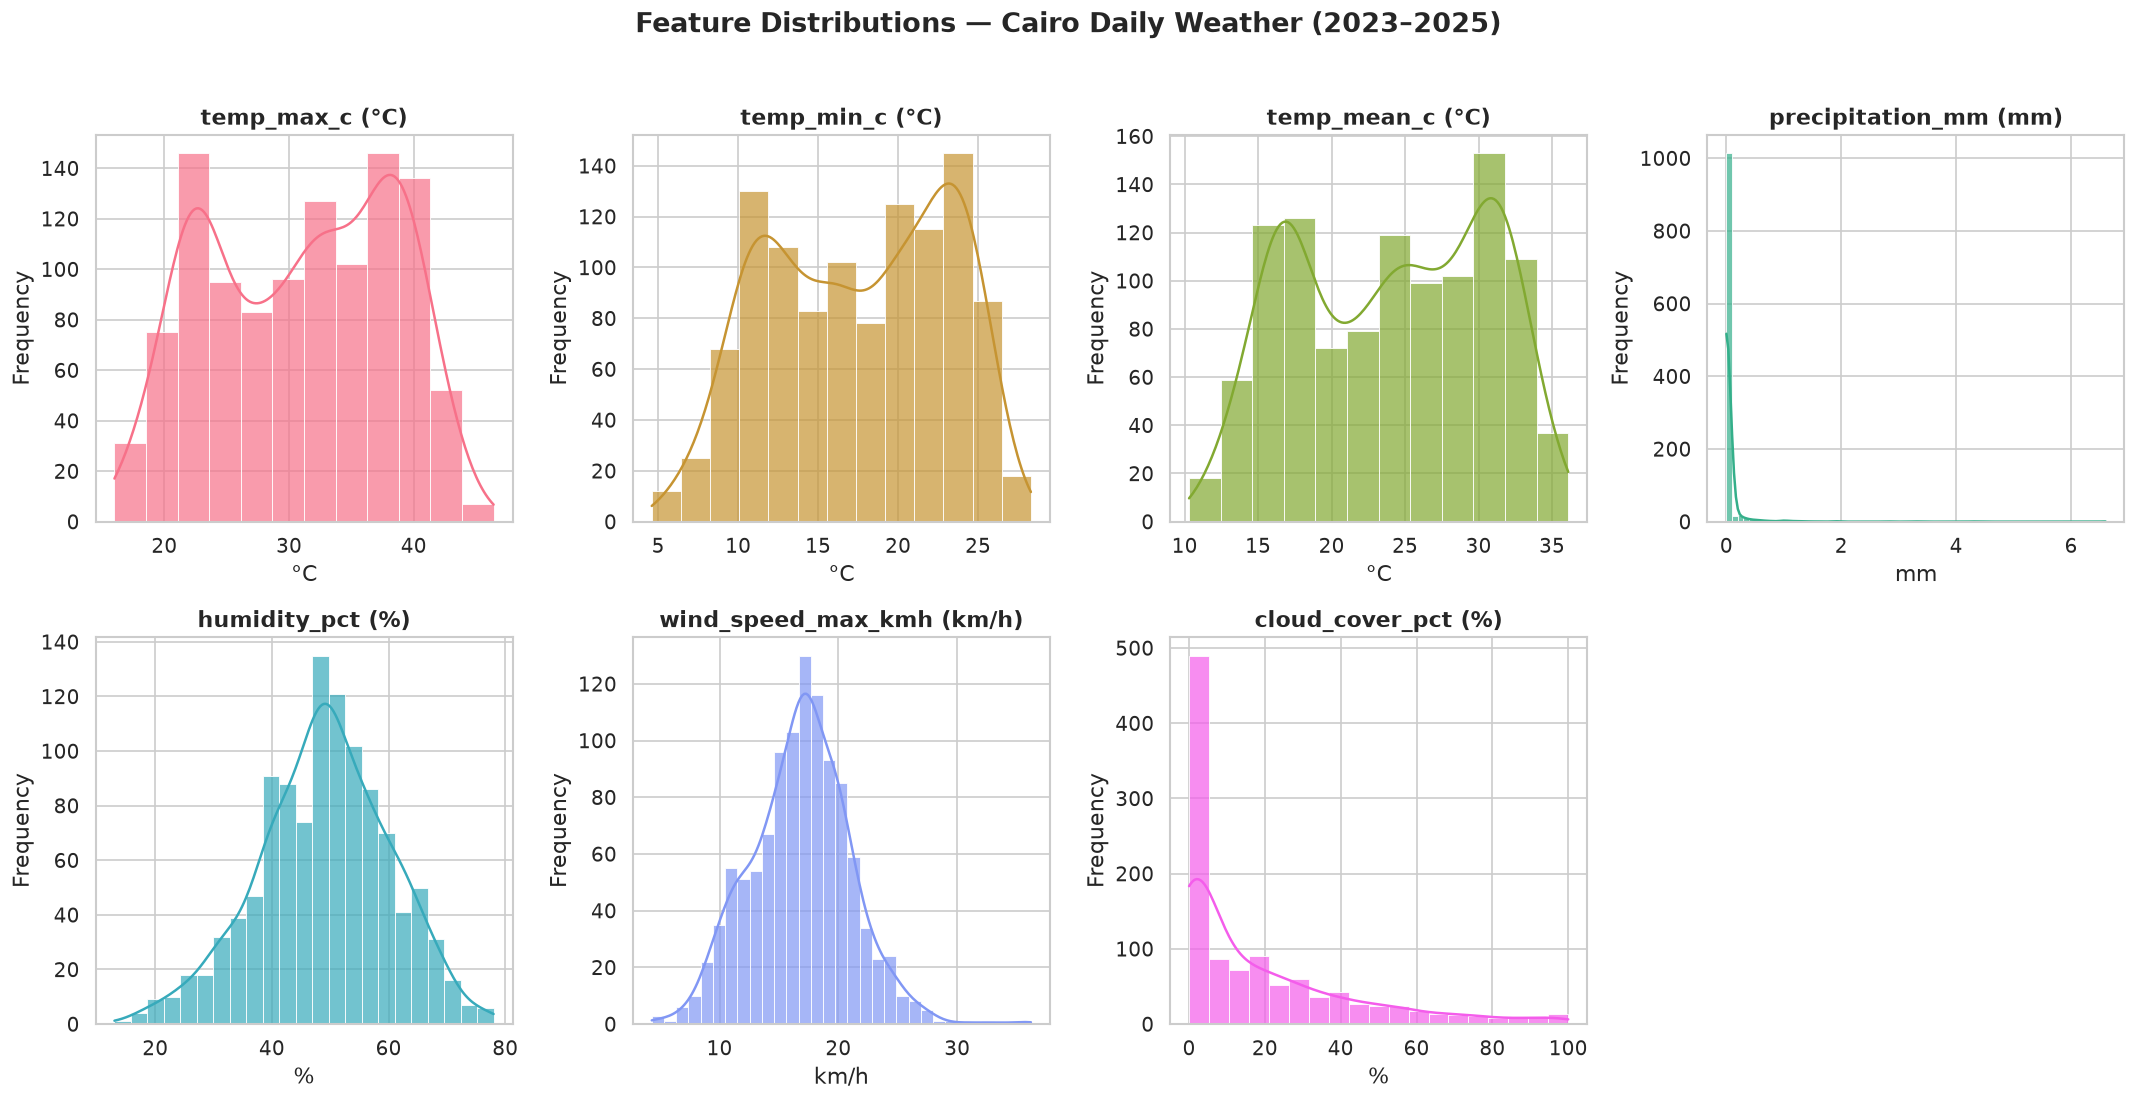

In [9]:
# Distribution plots (Histogram + KDE) for all variables
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

colors = sns.color_palette('husl', len(df.columns))
for i, col in enumerate(df.columns):
    ax = axes[i]
    sns.histplot(df[col].dropna(), kde=True, ax=ax, color=colors[i],
                 edgecolor='white', linewidth=0.5, alpha=0.7)
    ax.set_title(f'{col} ({config.UNITS.get(col, "")})', fontweight='bold')
    ax.set_xlabel(config.UNITS.get(col, col))
    ax.set_ylabel('Frequency')

# Hide last unused subplot
axes[-1].set_visible(False)

fig.suptitle('Feature Distributions — Cairo Daily Weather (2023–2025)',
             fontsize=16, fontweight='bold', y=1.02)
fig.tight_layout()
plt.show()

## 3.2 Temporal Dynamics

### Full-Span Time-Series Plots

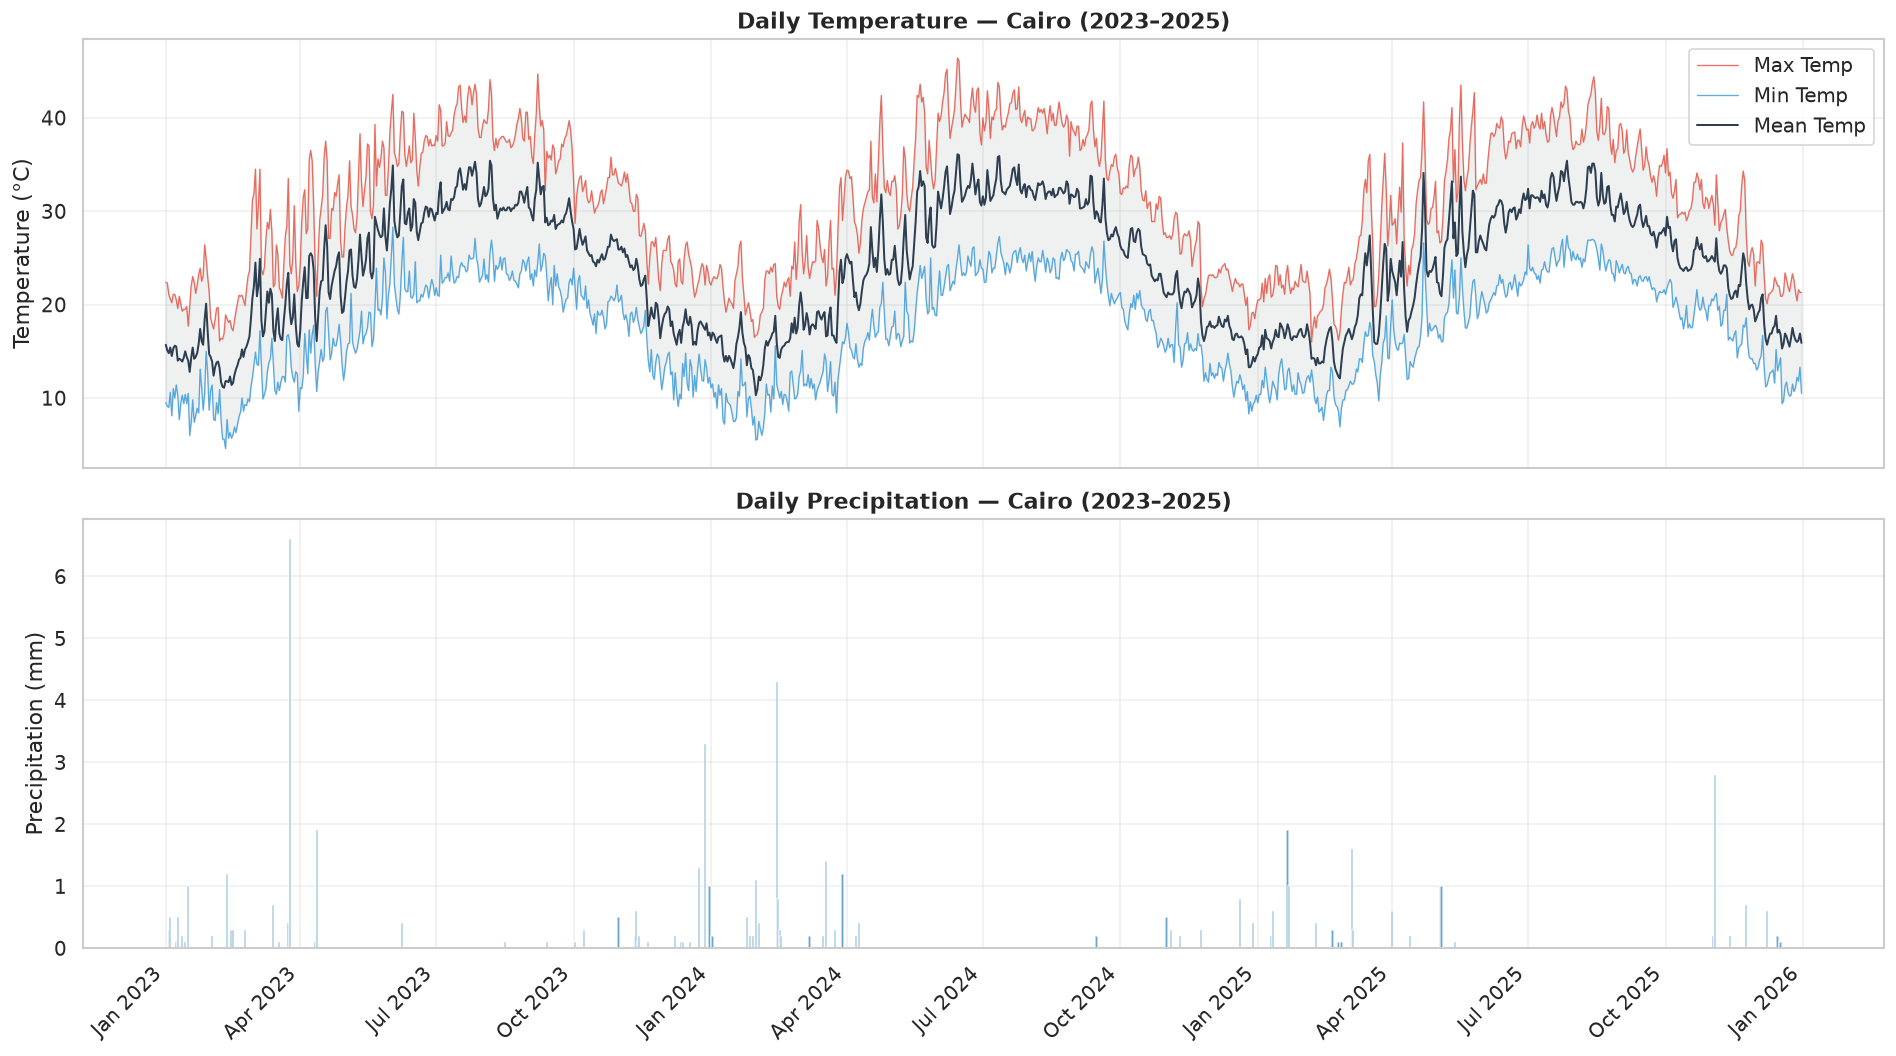

In [10]:
# Temperature time series with min/max range
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

ax1.plot(df.index, df['temp_max_c'], label='Max Temp', color='#e74c3c', alpha=0.8, linewidth=0.8)
ax1.plot(df.index, df['temp_min_c'], label='Min Temp', color='#3498db', alpha=0.8, linewidth=0.8)
ax1.plot(df.index, df['temp_mean_c'], label='Mean Temp', color='#2c3e50', linewidth=1.2)
ax1.fill_between(df.index, df['temp_min_c'], df['temp_max_c'], alpha=0.15, color='#95a5a6')
ax1.set_ylabel('Temperature (°C)')
ax1.set_title('Daily Temperature — Cairo (2023–2025)', fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Precipitation
ax2.bar(df.index, df['precipitation_mm'], color='#2980b9', alpha=0.7, width=1.5)
ax2.set_ylabel('Precipitation (mm)')
ax2.set_title('Daily Precipitation — Cairo (2023–2025)', fontweight='bold')
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right')
ax2.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

### Rolling Mean Trend Analysis

Applying 7-day and 30-day rolling windows to smooth out daily noise and reveal the underlying trend.

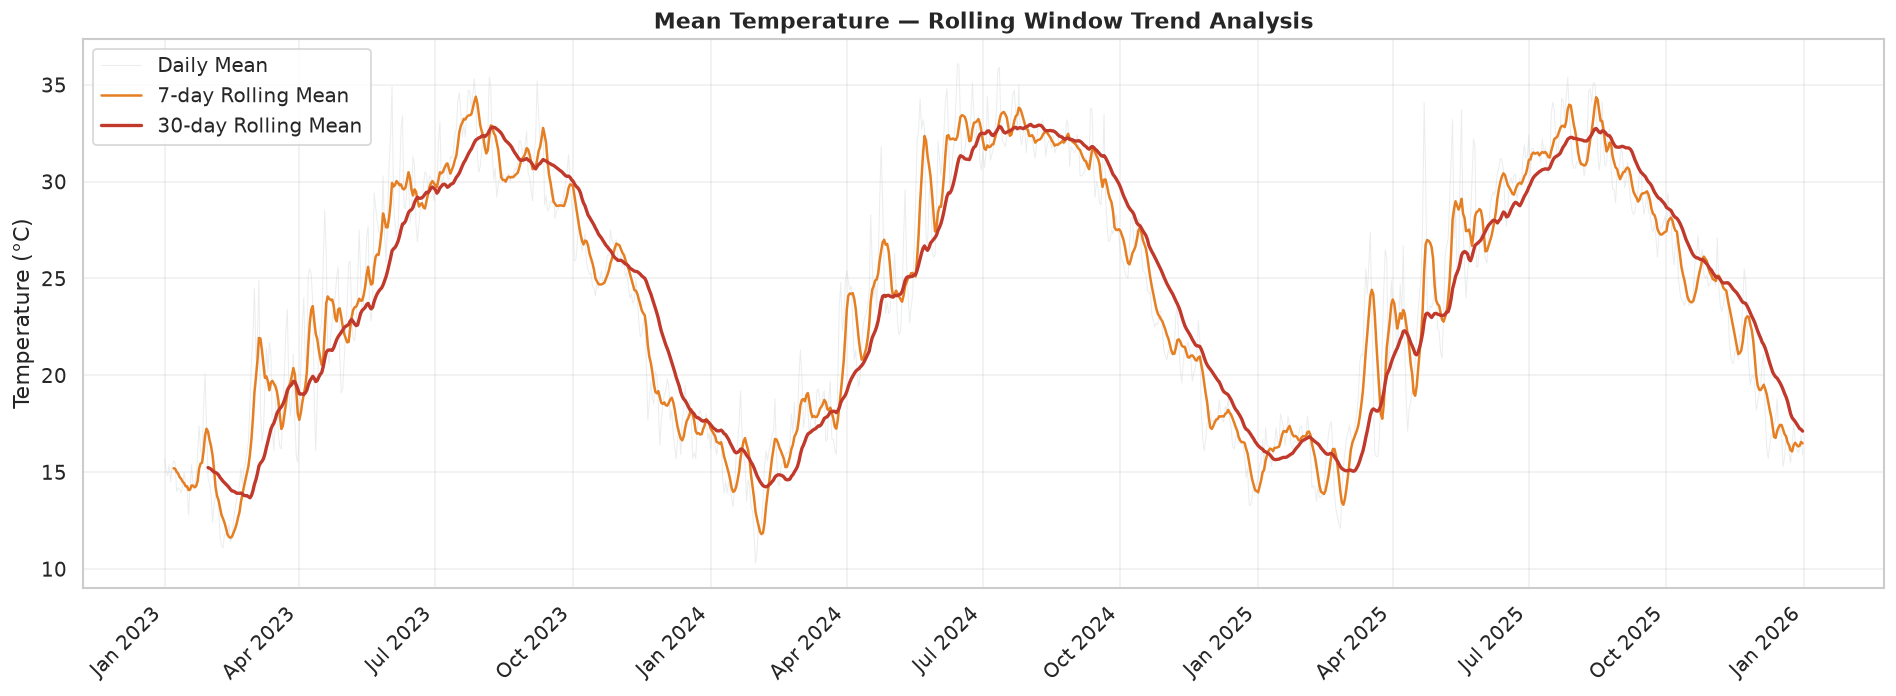

In [11]:
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(df.index, df['temp_mean_c'], alpha=0.3, color='#bdc3c7', linewidth=0.6, label='Daily Mean')
ax.plot(df.index, df['temp_mean_c'].rolling(7).mean(),
        color='#e67e22', linewidth=1.5, label='7-day Rolling Mean')
ax.plot(df.index, df['temp_mean_c'].rolling(30).mean(),
        color='#c0392b', linewidth=2.0, label='30-day Rolling Mean')

ax.set_ylabel('Temperature (°C)')
ax.set_title('Mean Temperature — Rolling Window Trend Analysis', fontweight='bold')
ax.legend()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

### Monthly Seasonality Boxplots

Grouping data by month reveals the annual cycle and the variability within each month.

INFO    | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO    | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO    | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO    | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


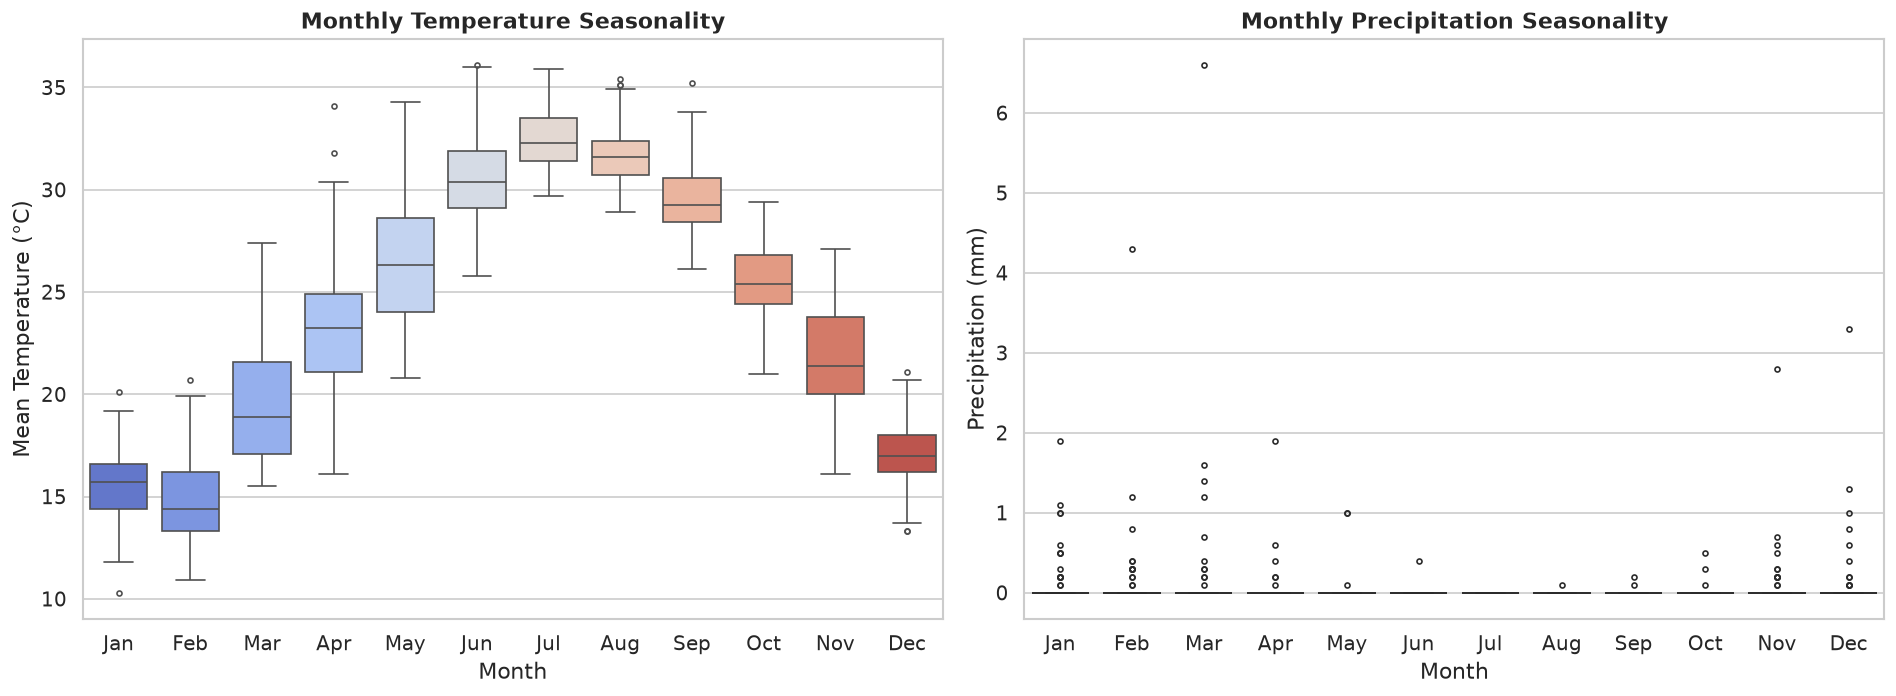

In [12]:
df_m = df.copy()
df_m['month_name'] = df_m.index.strftime('%b')

month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(x='month_name', y='temp_mean_c', hue='month_name',
            data=df_m, ax=ax1, order=month_order,
            palette='coolwarm', legend=False, fliersize=3)
ax1.set_xlabel('Month')
ax1.set_ylabel('Mean Temperature (°C)')
ax1.set_title('Monthly Temperature Seasonality', fontweight='bold')

sns.boxplot(x='month_name', y='precipitation_mm', hue='month_name',
            data=df_m, ax=ax2, order=month_order,
            palette='Blues', legend=False, fliersize=3)
ax2.set_xlabel('Month')
ax2.set_ylabel('Precipitation (mm)')
ax2.set_title('Monthly Precipitation Seasonality', fontweight='bold')

fig.tight_layout()
plt.show()

### Temperature Volatility

Rolling 30-day standard deviation captures how variable temperatures are across different seasons.

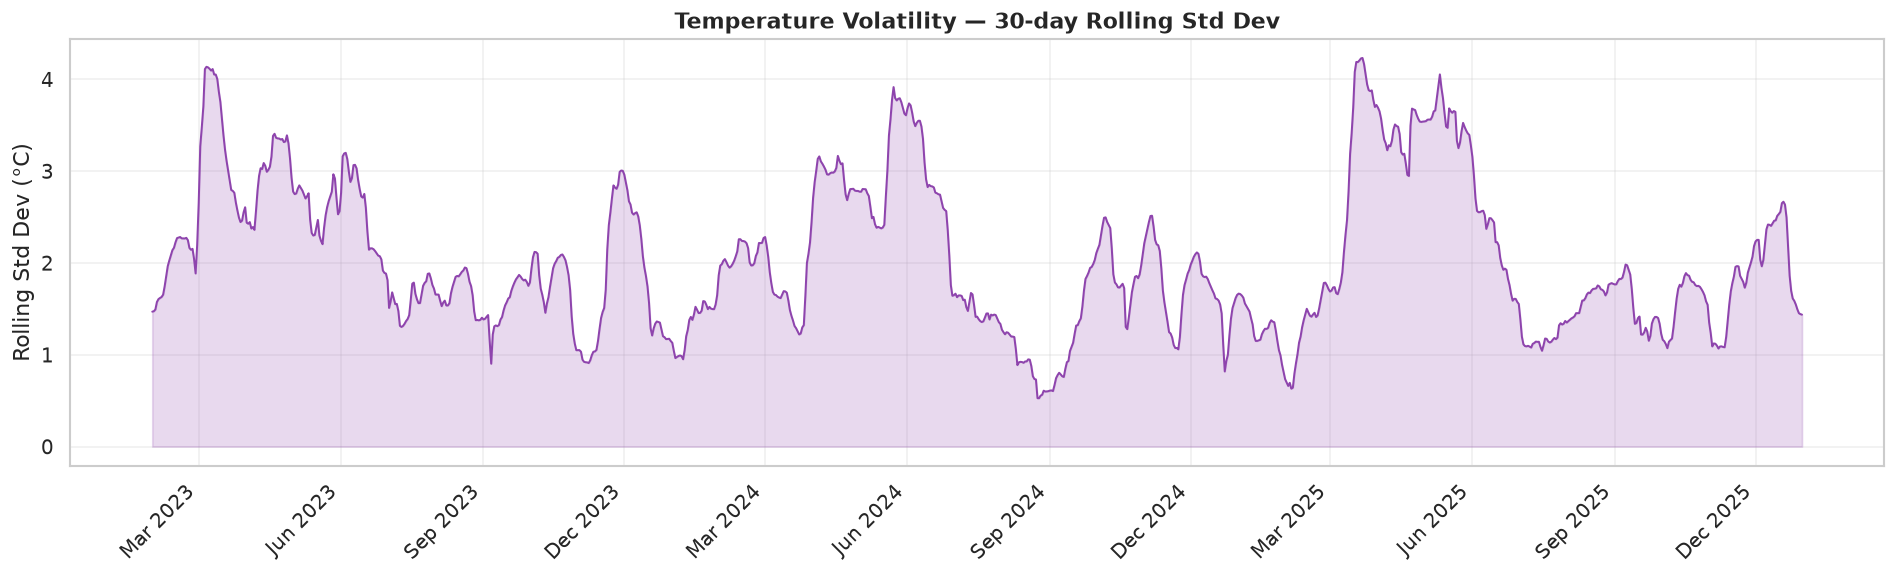

In [13]:
rolling_std = df['temp_mean_c'].rolling(30).std()

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df.index, rolling_std, color='#8e44ad', linewidth=1.2)
ax.fill_between(df.index, 0, rolling_std, alpha=0.2, color='#8e44ad')
ax.set_ylabel('Rolling Std Dev (°C)')
ax.set_title('Temperature Volatility — 30-day Rolling Std Dev', fontweight='bold')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 3.3 Decomposition & Structural Analysis

### Seasonal Decomposition

Decomposing mean temperature into **Trend**, **Seasonal**, and **Residual** components using classical additive decomposition (statsmodels seasonal_decompose, period=365).


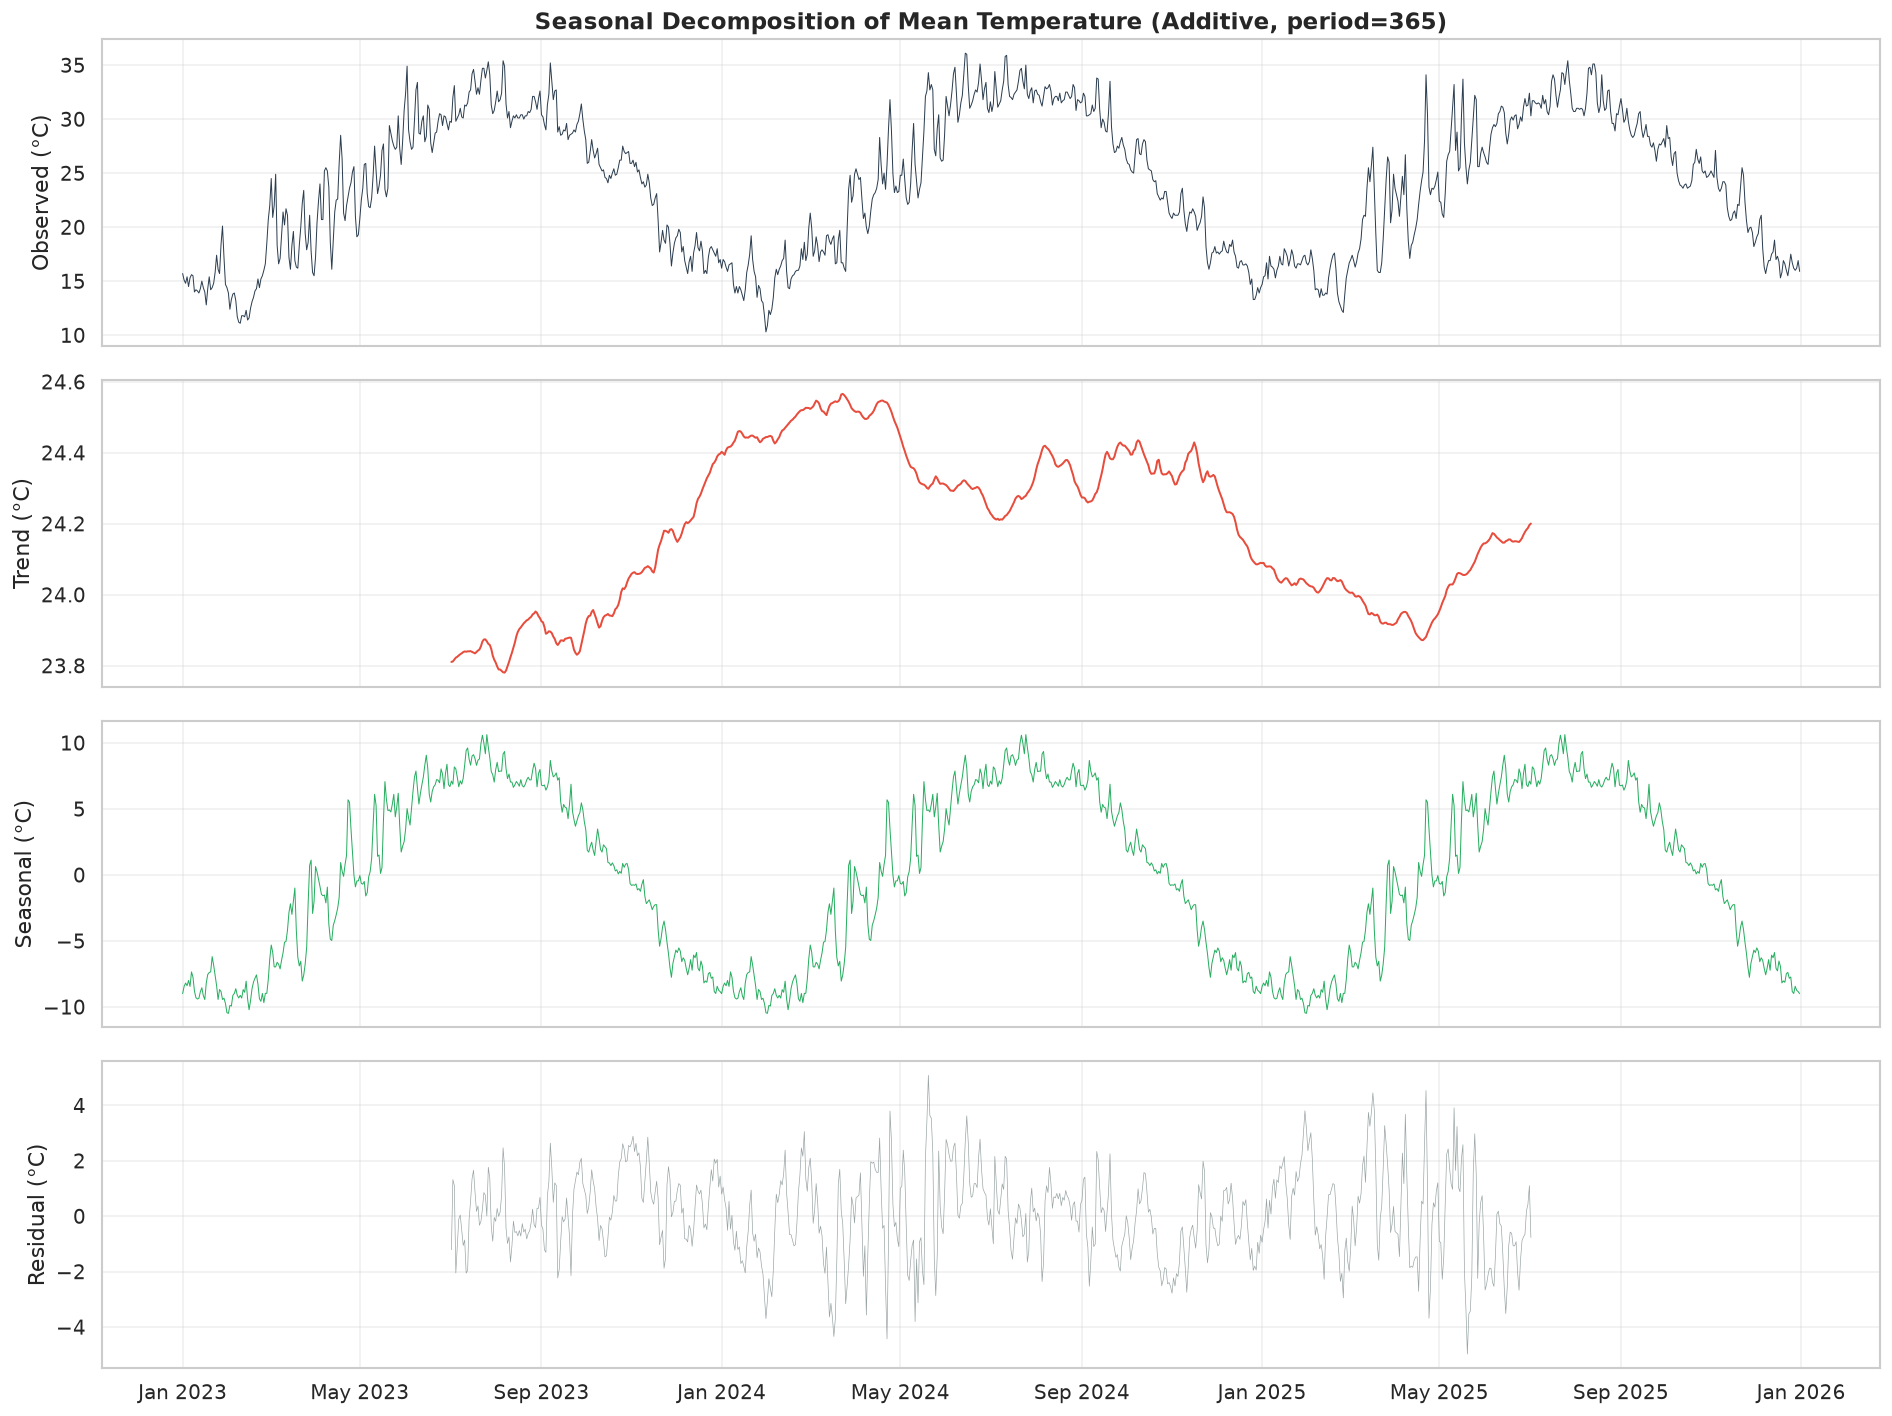

In [14]:
series = df['temp_mean_c'].dropna()
decomp = seasonal_decompose(series, model='additive', period=365)

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)

axes[0].plot(series.index, series.values, color='#2c3e50', linewidth=0.6)
axes[0].set_ylabel('Observed (°C)')
axes[0].set_title('Seasonal Decomposition of Mean Temperature (Additive, period=365)',
                  fontweight='bold', fontsize=14)

axes[1].plot(decomp.trend.index, decomp.trend.values, color='#e74c3c', linewidth=1.2)
axes[1].set_ylabel('Trend (°C)')

axes[2].plot(decomp.seasonal.index, decomp.seasonal.values, color='#27ae60', linewidth=0.6)
axes[2].set_ylabel('Seasonal (°C)')

axes[3].plot(decomp.resid.index, decomp.resid.values, color='#7f8c8d', linewidth=0.4, alpha=0.8)
axes[3].set_ylabel('Residual (°C)')
axes[3].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

### Autocorrelation (ACF) & Partial Autocorrelation (PACF)

These plots diagnose periodic lag dependencies in the temperature series. Strong periodic spikes indicate seasonal patterns that models must capture.

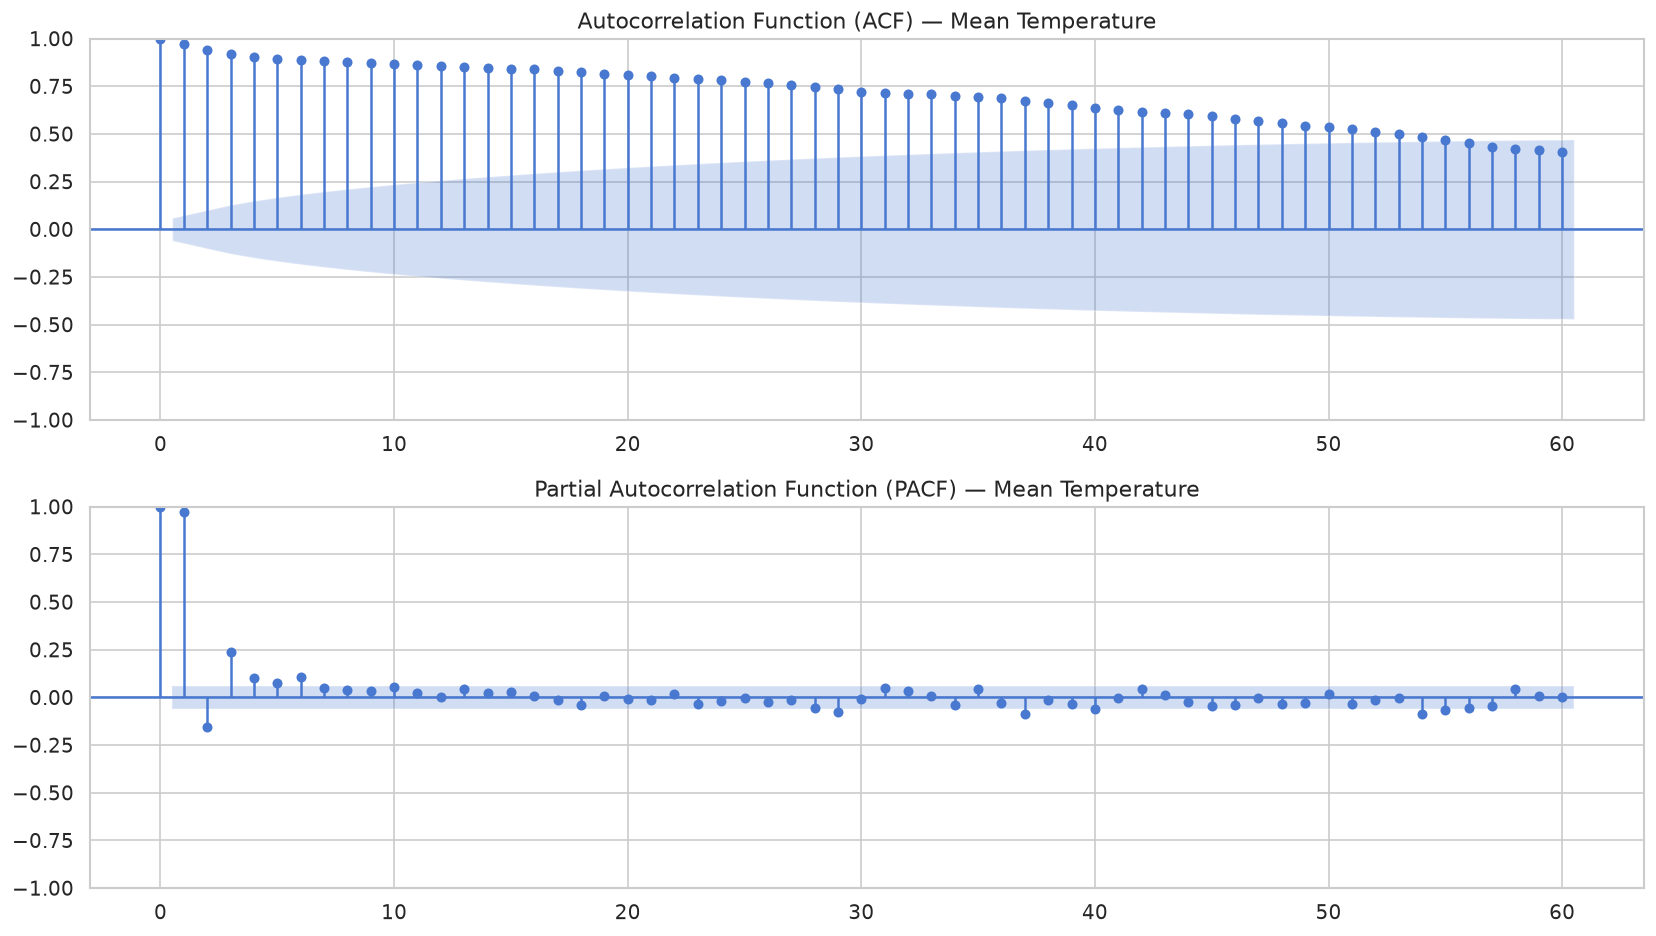

In [15]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(series, lags=60, ax=ax1, alpha=0.05,
         title='Autocorrelation Function (ACF) — Mean Temperature')
plot_pacf(series, lags=60, ax=ax2, alpha=0.05,
          title='Partial Autocorrelation Function (PACF) — Mean Temperature',
          method='ywm')

fig.tight_layout()
plt.show()

**ACF interpretation:** The slow, sinusoidal decay confirms strong positive autocorrelation at short lags (consecutive days are similar) and a seasonal pattern. This is characteristic of a non-stationary seasonal process.

**PACF interpretation:** Significant spikes at the first few lags suggest an AR component is appropriate. The pattern guides the choice of `p` in ARIMA/SARIMA models.

### Augmented Dickey-Fuller (ADF) Stationarity Test

In [16]:
# Comprehensive Stationarity Diagnostics: ADF & KPSS tests
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=InterpolationWarning)
from statsmodels.tsa.stattools import kpss

temp = df["temp_mean_c"].dropna()
diff1 = temp.diff().dropna()
diff365 = temp.diff(365).dropna()
precip = df["precipitation_mm"].dropna()

tests = [
    ("Mean Temperature — Raw Series", temp, "c"),
    ("Mean Temperature — First Difference (d=1)", diff1, "c"),
    (f"Mean Temperature — Seasonal Difference (D=1, s=365, leaves {len(diff365)} rows)", diff365, "c"),
]

for label, s, reg in tests:
    adf_res = adfuller(s, autolag="AIC", result_object=False)
    kpss_res = kpss(s, regression=reg, nlags="auto", result_object=False)
    print("")
    print("=" * 60)
    print(f"{label} (N={len(s)})")
    print("=" * 60)
    print(f"  ADF  : Stat = {adf_res[0]:.4f}, p-value = {adf_res[1]:.6f}, Lags = {adf_res[2]}")
    print(f"  KPSS : Stat = {kpss_res[0]:.4f}, p-value = {kpss_res[1]:.4f}")
    adf_stat = "Stationary" if adf_res[1] < 0.05 else "Non-Stationary (Fail to reject H0)"
    kpss_stat = "Stationary (Fail to reject H0)" if kpss_res[1] >= 0.05 else "Non-Stationary"
    print(f"  Verdict: ADF -> {adf_stat} | KPSS -> {kpss_stat}")

# Precipitation ADF
precip_adf = adfuller(precip, autolag="AIC", result_object=False)
print("")
print("=" * 60)
print(f"Precipitation — Raw Series (N={len(precip)})")
print("=" * 60)
print(f"  ADF  : Stat = {precip_adf[0]:.4f}, p-value = {precip_adf[1]:.6f}, Lags = {precip_adf[2]}")
print(f"  Verdict: Strongly Stationary (p < 0.05)")



Mean Temperature — Raw Series (N=1096)
  ADF  : Stat = -2.0139, p-value = 0.280521, Lags = 9
  KPSS : Stat = 0.2351, p-value = 0.1000
  Verdict: ADF -> Non-Stationary (Fail to reject H0) | KPSS -> Stationary (Fail to reject H0)

Mean Temperature — First Difference (d=1) (N=1095)
  ADF  : Stat = -15.1740, p-value = 0.000000, Lags = 8
  KPSS : Stat = 0.1501, p-value = 0.1000
  Verdict: ADF -> Stationary | KPSS -> Stationary (Fail to reject H0)

Mean Temperature — Seasonal Difference (D=1, s=365, leaves 731 rows) (N=731)
  ADF  : Stat = -9.4576, p-value = 0.000000, Lags = 2
  KPSS : Stat = 0.3906, p-value = 0.0812
  Verdict: ADF -> Stationary | KPSS -> Stationary (Fail to reject H0)

Precipitation — Raw Series (N=1096)
  ADF  : Stat = -30.5373, p-value = 0.000000, Lags = 0
  Verdict: Strongly Stationary (p < 0.05)


**Stationarity implications for modeling:**

- **Mean Temperature:** On the raw series, ADF fails to reject ( = 0.2805$) while KPSS does not reject stationarity ( = 0.1000$). The evidence is inconclusive and seasonality-driven rather than a clear unit root. Both first differencing (=1$: ADF  < 10^{-20}$, KPSS  = 0.10$) and seasonal differencing (=1, s=365$: ADF  < 10^{-15}$, KPSS  = 0.081$, leaving 731 rows) achieve stationarity. We recommend first differencing or Fourier/calendar cyclic features over seasonal differencing at lag 365, which incurs a steep penalty of 365 rows lost (one full year of training data).
- **Precipitation is stationary** ( pprox 0.0$) because it is an intermittent point process dominated by 94.0% dry days. Standard regression with MSE loss will suffer from zero-inflation bias; a two-stage hurdle model (classification for occurrence + regression for amount) or Tweedie loss is recommended.

---

## 3.4 Relationships & Anomalies

### Correlation Analysis


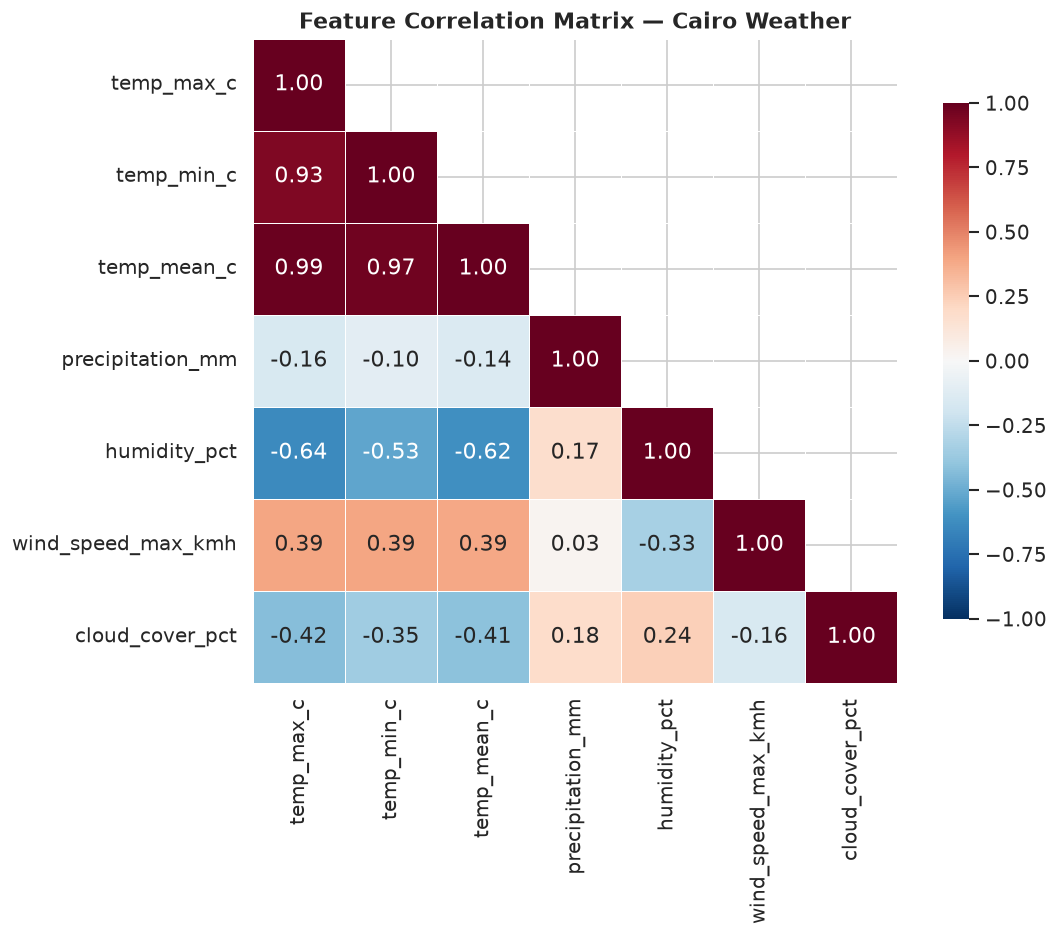


Strongest correlations (excluding self):
  temp_max_c                ↔ temp_mean_c              : +0.987
  temp_mean_c               ↔ temp_min_c               : +0.973
  temp_max_c                ↔ temp_min_c               : +0.932
  temp_max_c                ↔ humidity_pct             : -0.638
  temp_mean_c               ↔ humidity_pct             : -0.617


In [17]:
# Pearson correlation heatmap
corr = df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax, square=True,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
ax.set_title('Feature Correlation Matrix — Cairo Weather', fontweight='bold')
fig.tight_layout()
plt.show()

print('\nStrongest correlations (excluding self):')
corr_unstacked = corr.where(~np.eye(len(corr), dtype=bool)).unstack().dropna()
corr_sorted = corr_unstacked.abs().sort_values(ascending=False)
seen = set()
for (c1, c2), val in corr_sorted.items():
    pair = tuple(sorted([c1, c2]))
    if pair not in seen:
        seen.add(pair)
        actual = corr.loc[c1, c2]
        print(f'  {c1:25s} ↔ {c2:25s}: {actual:+.3f}')
    if len(seen) >= 5:
        break

### Rolling Z-Score Outlier Detection

Traditional Z-scores using the global mean would flag all summer days as "outliers" and all winter days as normal — ignoring seasonal structure. Instead, we use a **30-day rolling window** to compute local Z-scores, detecting values that are unusual *relative to their seasonal context*.

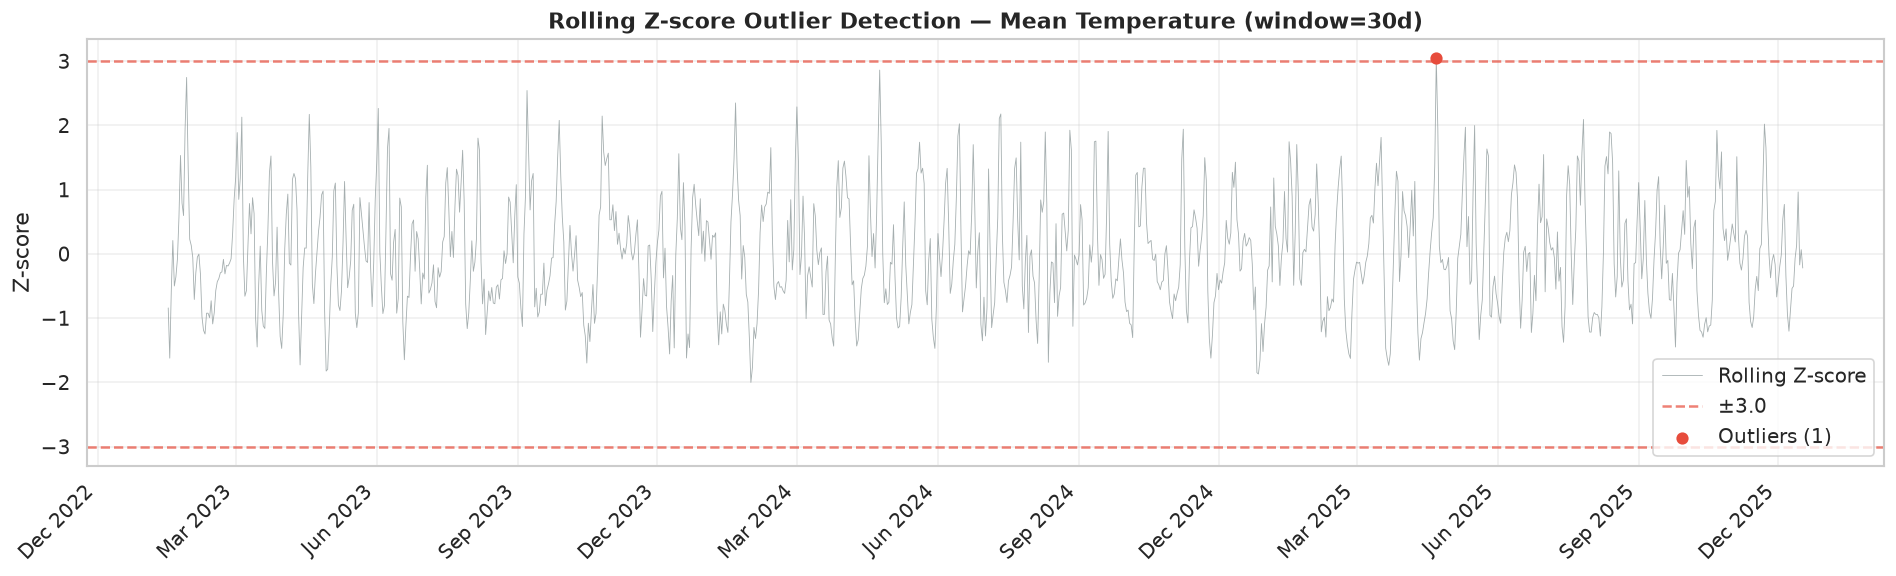


Outliers detected (1):
            temp_mean_c   z_score
date                             
2025-04-22         34.1  3.048948
Note: The 2025-04-22 thermal spike (34.1°C, Z = +3.05) is consistent with a Khamsin-type event; not externally verified.


In [18]:
# Rolling Z-score outlier detection
col = 'temp_mean_c'
window = 30
threshold = 3.0

rolling_mean = df[col].rolling(window, center=True).mean()
rolling_std_vals = df[col].rolling(window, center=True).std().replace(0, np.nan)
z_scores = (df[col] - rolling_mean) / rolling_std_vals
outlier_mask = z_scores.abs() > threshold

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df.index, z_scores, color='#7f8c8d', linewidth=0.5, alpha=0.7, label='Rolling Z-score')
ax.axhline(y=threshold, color='#e74c3c', linestyle='--', alpha=0.7, label=f'±{threshold}')
ax.axhline(y=-threshold, color='#e74c3c', linestyle='--', alpha=0.7)

if outlier_mask.any():
    ax.scatter(df.index[outlier_mask], z_scores[outlier_mask], color='#e74c3c',
               s=40, zorder=5, label=f'Outliers ({outlier_mask.sum()})')

ax.set_ylabel('Z-score')
ax.set_title(f'Rolling Z-score Outlier Detection — Mean Temperature (window={window}d)', fontweight='bold')
ax.legend()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# Print outliers
if outlier_mask.any():
    print(f'\nOutliers detected ({outlier_mask.sum()}):')
    outlier_df = df[outlier_mask][['temp_mean_c']].copy()
    outlier_df['z_score'] = z_scores[outlier_mask]
    print(outlier_df.to_string())
else:
    print('\nNo outliers detected.')
# Contextual interpretation note
print("Note: The 2025-04-22 thermal spike (34.1°C, Z = +3.05) is consistent with a Khamsin-type event; not externally verified.")


### Sanity Checks

Verifying data integrity against physical constraints to rule out sensor/API artifacts.

In [19]:
# Sanity checks
print('Data Sanity Checks')
print('=' * 50)

checks = {
    'Negative precipitation': (df['precipitation_mm'] < 0).sum(),
    'Temperature inversion (min > max)': (df['temp_min_c'] > df['temp_max_c']).sum(),
    'Humidity outside [0, 100]': ((df['humidity_pct'] < 0) | (df['humidity_pct'] > 100)).sum(),
    'Cloud cover outside [0, 100]': ((df['cloud_cover_pct'] < 0) | (df['cloud_cover_pct'] > 100)).sum(),
    'Temp > 55°C': (df['temp_max_c'] > 55).sum(),
    'Temp < -10°C': (df['temp_min_c'] < -10).sum(),
}

for check, count in checks.items():
    status = '✅' if count == 0 else f'⚠️ {count} violations'
    print(f'  {check:40s}: {status}')

print(f'\nOverall: {"ALL CHECKS PASSED" if all(v == 0 for v in checks.values()) else "ISSUES FOUND"}')

Data Sanity Checks
  Negative precipitation                  : ✅
  Temperature inversion (min > max)       : ✅
  Humidity outside [0, 100]               : ✅
  Cloud cover outside [0, 100]            : ✅
  Temp > 55°C                             : ✅
  Temp < -10°C                            : ✅

Overall: ALL CHECKS PASSED


---

# Summary & Next Steps

## Key Findings

1. **Strong annual seasonality** in temperature with a clean sinusoidal pattern — ideal for SARIMA or seasonal ML features
2. **Stationarity Diagnostics:** Temperature raw series is inconclusive/seasonally non-stationary (ADF p=0.28, KPSS p=0.10); first-differencing (d=1) and seasonal differencing (D=1, s=365) both achieve stationarity. First-differencing or Fourier terms are preferred over seasonal differencing at lag 365 to avoid losing 365 rows.
3. **Precipitation is stationary but zero-inflated** (94.0% dry days) — requires classification (rain/no-rain) + conditional regression (hurdle model / Tweedie)
4. **High feature correlation** — temperature variables are highly colinear; feature selection/PCA may be beneficial
5. **Data quality is verified** — raw API response contained 0 nulls (defensive imputation unexercised), 0 gaps, 0 duplicates, 1 contextual outlier in 3 years (2025-04-22, consistent with a Khamsin-type event; not externally verified)
6. **Splits Defined:** Planned training set (2023–2024) = 731 rows (leap year 2024); test set (2025) = 365 rows

## Next Steps (Future Phases)

- **Feature engineering:** Lag features, rolling statistics, seasonal indicators, Fourier terms
- **Baseline models:** Seasonal naïve, SARIMA, Prophet
- **ML models:** XGBoost, LSTM, Transformer-based architectures
- **Evaluation:** MAE, RMSE, MAPE with walk-forward cross-validation
- **Deployment:** API endpoint for real-time forecasts

---

*Data source: Open-Meteo Historical Weather API (ECMWF ERA5 reanalysis). Licensed under CC BY 4.0.*
